In [1]:
#!/usr/bin/env python3
# -*- coding: utf-8 -*-
"""
完整的机器学习分析 - 使用I_raw（保留正负号）
包含：
1. 数据加载和IR校正
2. 手动Backward Elimination（8个特征 -> 1个特征）
3. Grid Search超参数优化
4. 模型评估和SHAP分析
"""

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor
from sklearn.metrics import mean_squared_error, r2_score
import xgboost as xgb
import shap
import warnings
import os
import re

warnings.filterwarnings('ignore')

plt.rcParams['font.sans-serif'] = ['Arial']
plt.rcParams['axes.unicode_minus'] = False

def extract_elements_from_sample(sample_name):
    base_name = re.sub(r'\d+$', '', sample_name)
    parts = base_name.split('-')
    if len(parts) == 2:
        return parts[0], parts[1]
    else:
        return None, None

def extract_lsv_current_at_potential(target_potential=-1.0, lsv_data_dir=r'C:\Users\yibinjiang\Documents\GitHub\HD_separation\hd_separation_ml\data_extraction\all_data\LSV'):
    """从原始LSV文件提取电流（保留正负号）"""
    print(f"  Extracting LSV currents at {target_potential:.2f}V (preserving sign)...")
    
    lsv_currents = []
    original_potentials = np.arange(-0.92, -1.51, -0.02)
    
    for file in os.listdir(lsv_data_dir):
        if file.endswith('.txt'):
            sample = file.replace('.txt', '')
            lsv_file = os.path.join(lsv_data_dir, file)
            
            try:
                lsv_df = pd.read_csv(lsv_file, sep='\t')
                
                if 'Potential(V)' in lsv_df.columns and 'Current(A)' in lsv_df.columns:
                    potential = lsv_df['Potential(V)'].values
                    current = lsv_df['Current(A)'].values
                    
                    potential_reversed = potential[::-1]
                    current_reversed = current[::-1]
                    f_current = np.interp(original_potentials, potential_reversed, current_reversed)
                    
                    f_current_mA = f_current * 1000
                    idx = np.argmin(np.abs(original_potentials - target_potential))
                    current_at_target = f_current_mA[idx]
                    
                    lsv_currents.append({
                        'sample': sample,
                        f'I_at_{target_potential:.3f}V': current_at_target
                    })
                    
            except Exception as e:
                pass
    
    print(f"  Extracted {len(lsv_currents)} samples")
    return pd.DataFrame(lsv_currents)

def load_data(lsv_potential=-1.2):
    """
    加载并准备数据（不做因子分析，直接使用原始金属描述符）：
    1. Sheet1: work function / pzc / electronegativity / M-M / E(M-H) 等
    2. Sheet2: Adsorption Energies / Free Energy of Adsorption（按金属做晶面平均）
    3. 把以上 + E° 合在一起，直接作为金属描述符
    4. 对每个样品的 element1 / element2 映射这些金属描述符
    5. 特征 = EIS 特征 + I_raw + (金属描述符_element1/2)
    """
    print("\n" + "="*100)
    print("STEP 1: DATA LOADING AND PREPARATION (NO Factor Analysis)")
    print("="*100)

    # =========================
    # 1. 从 EH_extra.xlsx 读取 Sheet1 + Sheet2
    # =========================
    eh_file = "EH_extra.xlsx"
    print(f"\nReading metal descriptors from: {eh_file}")
    sheet1 = pd.read_excel(eh_file, sheet_name="Sheet1")
    sheet2 = pd.read_excel(eh_file, sheet_name="Sheet2")

    # ----- Sheet1 预处理 -----
    sheet1 = sheet1.rename(columns={
        "Unnamed: 0": "element",
        "Work function (eV)": "work_function",
        "pzc": "pzc",
        
        "M-M": "MM_bond",
        "E(M-H) (kJ/mol)": "MH_bond_kJ",
        "E(M-D) (kJ/mol)": "MD_bond_kJ",
        "delta_ZPE_H (eV)": "delta_ZPE_H"

    })

    for col in ["electronegativity", "work_function", "pzc", "MM_bond", "MH_bond_kJ", "delta_EOH","Frequency_H","Frequency_OH","Frequency_D","delta_ZPE_H", "MD_bond_kJ"]:
        sheet1[col] = pd.to_numeric(sheet1[col], errors="coerce")

    # ----- Sheet2：按金属求吸附自由能平均 -----
    sheet2 = sheet2.rename(columns={"Unnamed: 0": "element"})
    sheet2["element"] = sheet2["element"].ffill()
    ads_avg = (
        sheet2.groupby("element")["Free Energy of Adsorption (eV)"]
        .mean()
        .reset_index()
        .rename(columns={"Free Energy of Adsorption (eV)": "FE_ads_avg"})
    )

    print("\nSheet2 element-averaged adsorption (first few rows):")
    print(ads_avg.head())

    # 合并 Sheet1 + Sheet2 (每个元素一行)
    metal_df = pd.merge(sheet1, ads_avg, on="element", how="left")

    # =========================
    # 2. 加上 E° 描述符
    # =========================
    E_std_dict = {
        "Ag": 0.80, "Al": -1.66, "Au": 1.52, "Ba": -2.91, "Ca": -2.87,
        "Cd": -0.40, "Ce": -2.34, "Co": -0.28, "Cr": -0.74, "Cu": 0.34,
        "Eu": -2.81, "Fe": -0.44, "Ga": -0.53, "In": -0.34, "La": -2.38,
        "Mg": -2.37, "Mn": -1.19, "Mo": -0.20, "Nb": -1.10, "Ni": -0.25,
        "Pb": -0.13, "Pd": 0.92, "Pt": 1.20, "Ru": 0.455, "Sc": -2.08,
        "Sr": -2.90, "V": -1.18, "W": -0.12, "Y": -2.37, "Zn": -0.76,
    }
    metal_df["E_std"] = metal_df["element"].map(E_std_dict)

    for col in metal_feature_cols:
        metal_df[col] = pd.to_numeric(metal_df[col], errors="coerce")

    # 构造 element -> 描述符 的映射字典
    metal_desc_dicts = {
        col: metal_df.set_index("element")[col].to_dict()
        for col in metal_feature_cols
    }

    # =========================
    # 4. 加载 ML 样本数据：overpotential / 拟合结果 / LSV
    # =========================
    potential_data = pd.read_csv('sample_overpotentials_new_corrected_verison.csv')
    print(f"\nTotal samples: {len(potential_data)}")

    noble_metals = []
    noble_metal_samples = []
    for idx, row in potential_data.iterrows():
        sample = row['sample']
        element1, element2 = extract_elements_from_sample(sample)
        if element1 in noble_metals or element2 in noble_metals:
            noble_metal_samples.append(sample)
        if sample[-1].isdigit():
            noble_metal_samples.append(sample)

    potential_data = potential_data[~potential_data['sample'].isin(noble_metal_samples)].copy()
    print(f"After removing {len(noble_metal_samples)} noble/Bayesian samples: {len(potential_data)}")

    fitting_results = pd.read_csv('independent_fitting_results.csv')

    print(f"\nSamples with fitted EIS data: {len(fitting_results)}")

    lsv_current_df = extract_lsv_current_at_potential(target_potential=lsv_potential)

    print(f"\nSamples with LSV current data: {len(lsv_current_df)}")

    merged_df = pd.merge(potential_data, fitting_results, on='sample', how='inner')
    merged_df = pd.merge(merged_df, lsv_current_df, on='sample', how='inner')
    print(f"After merging: {merged_df.shape[0]} samples")

    # =========================
    # 5. IR 校正 & EIS 特征
    # =========================
    merged_df['E_IR_corrected'] = merged_df['E_actual (V)'] + merged_df['Rs (Ohm)'] * 0.05 * 0.9
    print("IR correction applied: E_IR_corrected = E_actual + Rs * 0.05 * 0.9")

    merged_df['roughness_factor_limited'] = merged_df['roughness_factor'].clip(upper=200)
    merged_df['A_normalized'] = merged_df['A'] / merged_df['roughness_factor_limited']
    merged_df['B_normalized'] = merged_df['B'] / merged_df['roughness_factor_limited']
    merged_df['Rct'] = 1 / merged_df['A_normalized']
    merged_df['Cp'] = -(merged_df['A_normalized']**2) / merged_df['B_normalized']
    merged_df['Rp'] = -1 / (merged_df['A_normalized']**2 * merged_df['C'] / merged_df['B_normalized'] + merged_df['A_normalized'])

    j = 0.01
    ln10 = 2.303
    merged_df['tafel_slope'] = ln10 * j * (merged_df['Rct'] + merged_df['Rp']) / merged_df['roughness_factor_limited'] * 1000
    merged_df['tafel_slope_limited'] = merged_df['tafel_slope'].clip(lower=0, upper=500)

    # =========================
    # 6. 从 sample 名中提取 element1 / element2，并映射金属描述符（非 FA）
    # =========================
    merged_df[['element1', 'element2']] = merged_df['sample'].apply(
        lambda s: pd.Series(extract_elements_from_sample(s))
    )

    metal_descriptor_cols = []
    for desc_col in metal_feature_cols:
        col1 = f"{desc_col}_element1"
        col2 = f"{desc_col}_element2"

        merged_df[col1] = merged_df['element1'].map(metal_desc_dicts[desc_col])
        merged_df[col2] = merged_df['element2'].map(metal_desc_dicts[desc_col])

        # 缺失用全局中位数填补
        all_vals = pd.concat([merged_df[col1], merged_df[col2]], axis=0)
        median_val = all_vals.median()
        merged_df[col1] = merged_df[col1].fillna(median_val)
        merged_df[col2] = merged_df[col2].fillna(median_val)

        metal_descriptor_cols.extend([col1, col2])

    print(f"Added metal descriptor columns (NO FA): {metal_descriptor_cols}")

    # =========================
    # 7. 组装特征矩阵 X / 目标 y
    # =========================
    lsv_current_col = [col for col in merged_df.columns if col.startswith('I_at_')][0]
    print(f"Using LSV current column: {lsv_current_col}")

    print("\nRaw current statistics:")
    print(f"  Range: {merged_df[lsv_current_col].min():.2f} ~ {merged_df[lsv_current_col].max():.2f} mA/cm2")
    print(f"  Mean: {merged_df[lsv_current_col].mean():.2f} mA/cm2")
    print(f"  Positive: {(merged_df[lsv_current_col] > 0).sum()} samples")
    print(f"  Negative: {(merged_df[lsv_current_col] < 0).sum()} samples")

    electrochemical_features = [
        'Rct', 'Cp', 'Rp', 'C_dl', 'E_IR_corrected',
        'tafel_slope_limited', 'W_sigma', lsv_current_col
    ]

    all_raw_features = electrochemical_features + metal_descriptor_cols
    X = merged_df[all_raw_features].copy()
    y = merged_df['separation_coefficient'].copy()

    valid_mask = ~(X.isnull().any(axis=1) | y.isnull())
    X = X[valid_mask]
    y = y[valid_mask]
    print(f"After removing NaN: {X.shape[0]} samples")

    # =========================
    # 8. 对数变换 + I_raw，构造最终特征列表
    # =========================
    X['Rct_log'] = np.log1p(np.abs(X['Rct'])) * np.sign(X['Rct'])
    X['Rp_log'] = np.log1p(np.abs(X['Rp'])) * np.sign(X['Rp'])
    X['C_dl_log'] = np.log1p(X['C_dl'])
    X['Cp_log'] = np.log1p(np.abs(X['Cp'])) * np.sign(X['Cp'])
    X['W_sigma_log'] = np.log1p(X['W_sigma'])
    X['tafel_slope'] = X['tafel_slope_limited']
    X['E_IR_corrected_final'] = X['E_IR_corrected']
    X['I_raw'] = X[lsv_current_col]

    feature_columns_final = [
        'Rct_log', 'Cp_log', 'Rp_log', 'C_dl_log',
        'E_IR_corrected_final', 'tafel_slope',
        'W_sigma_log', 'I_raw'
    ] + metal_descriptor_cols

    X = X[feature_columns_final]

    print(f"\nFinal features ({X.shape[1]}): {X.columns.tolist()}")
    print("Note: Using I_raw + EIS features + raw metal descriptors "
          "(Sheet1 + Sheet2, element-averaged adsorption included, NO FA)")
    element1_labels = merged_df.loc[X.index, 'element1']

    return X, y, element1_labels

def manual_backward_elimination(X_train, y_train, min_features=1):
    """手动Backward Elimination"""
    print("\n" + "="*100)
    print("STEP 2: MANUAL BACKWARD ELIMINATION (8 -> 1 features)")
    print("="*100)
    
    estimator = RandomForestRegressor(
        n_estimators=200,
        max_depth=10,
        min_samples_leaf=2,
        min_samples_split=2,
        random_state=42,
        n_jobs=-1
    )
    
    print(f"\nEstimator: Random Forest (optimized parameters)")
    print(f"Starting with {X_train.shape[1]} features")
    
    current_features = list(X_train.columns)
    elimination_history = []
    
    step = 0
    while len(current_features) > min_features:
        step += 1
        print(f"\n{'='*80}")
        print(f"Step {step}: {len(current_features)} features")
        print(f"{'='*80}")
        
        X_current = X_train[current_features]
        current_score = cross_val_score(estimator, X_current, y_train, cv=5, scoring='r2', n_jobs=-1).mean()
        
        print(f"Current features: {current_features}")
        print(f"Current CV R2: {current_score:.4f}")
        
        elimination_history.append({
            'step': step,
            'n_features': len(current_features),
            'features': current_features.copy(),
            'cv_r2': current_score
        })
        
        print(f"\nTrying to remove each feature:")
        best_score_after_removal = -np.inf
        worst_feature = None
        
        for feature in current_features:
            temp_features = [f for f in current_features if f != feature]
            X_temp = X_train[temp_features]
            temp_score = cross_val_score(estimator, X_temp, y_train, cv=5, scoring='r2', n_jobs=-1).mean()
            
            print(f"  Remove '{feature}': CV R2 = {temp_score:.4f} (change: {temp_score - current_score:+.4f})")
            
            if temp_score > best_score_after_removal:
                best_score_after_removal = temp_score
                worst_feature = feature
        
        print(f"\n>>> Removing '{worst_feature}'")
        current_features.remove(worst_feature)
    
    # 最后1个特征
    step += 1
    X_final = X_train[current_features]
    final_score = cross_val_score(estimator, X_final, y_train, cv=5, scoring='r2', n_jobs=-1).mean()
    
    elimination_history.append({
        'step': step,
        'n_features': len(current_features),
        'features': current_features.copy(),
        'cv_r2': final_score
    })
    
    print(f"\n{'='*80}")
    print(f"Final: {len(current_features)} feature(s)")
    print(f"{'='*80}")
    print(f"Feature: {current_features}")
    print(f"CV R2: {final_score:.4f}")
    
    return elimination_history

def plot_elimination_curve(elimination_history, output_dir):
    """绘制消除曲线"""
    print("\n" + "="*100)
    print("PLOTTING ELIMINATION CURVE")
    print("="*100)
    
    history_df = pd.DataFrame(elimination_history)
    
    plt.figure(figsize=(14, 8))
    plt.plot(history_df['n_features'], history_df['cv_r2'], 'o-', linewidth=3, markersize=14, color='steelblue')
    
    for idx, row in history_df.iterrows():
        plt.annotate(f"{row['cv_r2']:.4f}", 
                    (row['n_features'], row['cv_r2']),
                    textcoords="offset points", 
                    xytext=(0,15), 
                    ha='center',
                    fontsize=11,
                    fontweight='bold',
                    bbox=dict(boxstyle='round,pad=0.3', facecolor='yellow', alpha=0.7))
    
    max_idx = history_df['cv_r2'].idxmax()
    max_row = history_df.loc[max_idx]
    plt.plot(max_row['n_features'], max_row['cv_r2'], 'r*', markersize=35, 
             label=f"Best: {max_row['n_features']} features (CV R2={max_row['cv_r2']:.4f})", zorder=5)
    
    plt.xlabel('Number of Features', fontsize=15, fontweight='bold')
    plt.ylabel('Cross-Validation R2 Score', fontsize=15, fontweight='bold')
    plt.title('Manual Backward Elimination (Using I_raw with sign)\n(8 features -> 1 feature)', 
             fontsize=17, fontweight='bold')
    plt.grid(True, alpha=0.4, linestyle='--')
    plt.legend(fontsize=13, loc='best')
    plt.xticks(history_df['n_features'].values, fontsize=12)
    
    y_min = history_df['cv_r2'].min() - 0.05
    y_max = history_df['cv_r2'].max() + 0.08
    plt.ylim(y_min, y_max)
    
    plt.tight_layout()
    plot_file = os.path.join(output_dir, 'backward_elimination_I_raw.png')
    plt.savefig(plot_file, dpi=300, bbox_inches='tight')
    print(f"[OK] Elimination curve saved to: {plot_file}")
    plt.show()
    plt.close()
    
    # 保存历史
    history_detail = []
    for idx, row in history_df.iterrows():
        history_detail.append({
            'step': row['step'],
            'n_features': row['n_features'],
            'cv_r2': row['cv_r2'],
            'features': ', '.join(row['features'])
        })
    
    detail_df = pd.DataFrame(history_detail)
    history_file = os.path.join(output_dir, 'backward_elimination_I_raw_history.csv')
    detail_df.to_csv(history_file, index=False)
    print(f"[OK] History saved to: {history_file}")
    
    return history_df

def train_models_with_selected_features(X_train, X_test, y_train, y_test, selected_features, output_dir):
    """使用选中的特征训练模型（含Grid Search）"""
    print("\n" + "="*100)
    print("STEP 3: TRAINING MODELS WITH SELECTED FEATURES (Grid Search)")
    print("="*100)
    
    X_train_selected = X_train[selected_features].reset_index(drop=True)
    X_test_selected = X_test[selected_features].reset_index(drop=True)
    y_train = y_train.reset_index(drop=True)
    y_test = y_test.reset_index(drop=True)
    
    print(f"\nUsing {len(selected_features)} selected features:")
    for i, feat in enumerate(selected_features, 1):
        print(f"  {i}. {feat}")
    
    models_config = {
        'Random Forest': {
            'model': RandomForestRegressor(random_state=42),
            'params': {
                'n_estimators': [100, 200],
                'max_depth': [10, 15, None],
                'min_samples_split': [2, 5],
                'min_samples_leaf': [1, 2]
            }
        },
        'Extra Trees': {
            'model': ExtraTreesRegressor(random_state=42),
            'params': {
                'n_estimators': [100, 200],
                'max_depth': [10, 15, None],
                'min_samples_split': [2, 5],
                'min_samples_leaf': [1, 2]
            }
        },
        'XGBoost': {
            'model': xgb.XGBRegressor(random_state=42),
            'params': {
                'n_estimators': [50, 100, 200],
                'max_depth': [3, 5, 7],
                'learning_rate': [0.05, 0.1],
                'subsample': [0.8, 1.0]
            }
        }
    }
    
    results = []
    best_model = None
    best_score = -np.inf
    
    for model_name, config in models_config.items():
        print(f"\n--- {model_name} ---")
        
        try:
            grid_search = GridSearchCV(
                config['model'],
                config['params'],
                cv=5,
                scoring='r2',
                n_jobs=-1,
                verbose=0
            )
            
            grid_search.fit(X_train_selected, y_train)
            
            print(f"Best params: {grid_search.best_params_}")
            print(f"Best CV score: {grid_search.best_score_:.4f}")
            
            model = grid_search.best_estimator_
            
            y_train_pred = model.predict(X_train_selected)
            y_test_pred = model.predict(X_test_selected)
            
            train_r2 = r2_score(y_train, y_train_pred)
            test_r2 = r2_score(y_test, y_test_pred)
            train_rmse = np.sqrt(mean_squared_error(y_train, y_train_pred))
            test_rmse = np.sqrt(mean_squared_error(y_test, y_test_pred))
            
            print(f"Train R2: {train_r2:.4f}, RMSE: {train_rmse:.4f}")
            print(f"Test R2: {test_r2:.4f}, RMSE: {test_rmse:.4f}")
            print(f"Overfitting: {train_r2 - test_r2:.4f}")
            
            results.append({
                'model_name': model_name,
                'best_params': str(grid_search.best_params_),
                'best_cv_score': grid_search.best_score_,
                'train_r2': train_r2,
                'test_r2': test_r2,
                'train_rmse': train_rmse,
                'test_rmse': test_rmse,
                'overfitting': train_r2 - test_r2,
                'model': model,
                'y_train': y_train,
                'y_test': y_test,
                'y_train_pred': y_train_pred,
                'y_test_pred': y_test_pred
            })
            
            if test_r2 > best_score:
                best_score = test_r2
                best_model = results[-1]
                best_model['X_train'] = X_train_selected
                best_model['X_test'] = X_test_selected
                best_model['features'] = selected_features
            
        except Exception as e:
            print(f"[ERROR] {model_name} failed: {e}")
    
    results_df = pd.DataFrame(results)
    results_df = results_df.sort_values('test_r2', ascending=False)
    
    print(f"\n{'='*100}")
    print(f"MODEL PERFORMANCE RANKING")
    print(f"{'='*100}")
    print(results_df[['model_name', 'best_cv_score', 'test_r2', 'test_rmse', 'overfitting']].to_string(index=False))
    
    results_file = os.path.join(output_dir, 'final_ml_I_raw_results.csv')
    results_df[['model_name', 'best_params', 'best_cv_score', 'train_r2', 'test_r2', 'train_rmse', 'test_rmse', 'overfitting']].to_csv(results_file, index=False)
    print(f"\n[OK] Results saved to: {results_file}")
    
    return best_model, results_df

def plot_prediction(best_model, output_dir):
    """绘制预测图"""
    print("\n" + "="*100)
    print("STEP 4: PLOTTING PREDICTION VS TRUE")
    print("="*100)
    
    fig, axes = plt.subplots(1, 2, figsize=(16, 7))
    
    ax = axes[0]
    ax.scatter(best_model['y_test'], best_model['y_test_pred'], alpha=0.6, s=50, color='orange', edgecolors='k', linewidth=0.5)
    
    min_val = min(best_model['y_test'].min(), best_model['y_test_pred'].min())
    max_val = max(best_model['y_test'].max(), best_model['y_test_pred'].max())
    ax.plot([min_val, max_val], [min_val, max_val], 'r--', linewidth=2, label='Perfect prediction')
    
    ax.set_xlabel('True Separation Coefficient', fontsize=13)
    ax.set_ylabel('Predicted Separation Coefficient', fontsize=13)
    ax.set_title(f'Test Set\nR2 = {best_model["test_r2"]:.4f}, RMSE = {best_model["test_rmse"]:.4f}', 
                 fontsize=14, fontweight='bold')
    ax.legend(fontsize=11)
    ax.grid(alpha=0.3)
    ax.set_aspect('equal', adjustable='box')
    
    ax = axes[1]
    residuals = best_model['y_test'] - best_model['y_test_pred']
    ax.scatter(best_model['y_test_pred'], residuals, alpha=0.6, s=50, color='orange', edgecolors='k', linewidth=0.5)
    ax.axhline(y=0, color='r', linestyle='--', linewidth=2)
    ax.set_xlabel('Predicted Separation Coefficient', fontsize=13)
    ax.set_ylabel('Residuals', fontsize=13)
    ax.set_title(f'Residual Plot', fontsize=14, fontweight='bold')
    ax.grid(alpha=0.3)
    
    fig.suptitle(f'{best_model["model_name"]} - {len(best_model["features"])} Features (I_raw)', 
                fontsize=16, fontweight='bold', y=0.98)
    
    plt.tight_layout()
    pred_file = os.path.join(output_dir, 'final_prediction_I_raw.png')
    plt.savefig(pred_file, dpi=300, bbox_inches='tight')
    print(f"[OK] Prediction plot saved to: {pred_file}")
    plt.show()
    plt.close()

def perform_shap_analysis(best_model, output_dir):
    print("\n" + "="*100)
    print("STEP 5: SHAP ANALYSIS")
    print("="*100)

    try:
        import shutil
        shap_dir = os.path.join(output_dir, 'final_shap_I_raw')
        if os.path.exists(shap_dir):
            shutil.rmtree(shap_dir)
        os.makedirs(shap_dir, exist_ok=True)

        # ---------- NEW: check both train and test ----------
        for name in ['X_train', 'X_test']:
            if name not in best_model:
                continue

            df = best_model[name].copy()
            print(f"\n[DEBUG] dtypes of {name} before SHAP:")
            print(df.dtypes)

            bad_columns = []

            for col in df.columns:
                coerced = pd.to_numeric(df[col], errors='coerce')
                bad_mask = coerced.isna() & df[col].notna()

                if bad_mask.any():
                    bad_columns.append(col)
                    print(f"\n[DEBUG] Non-numeric values detected in {name}.{col}")
                    print(df.loc[bad_mask, col].head(20))

            if bad_columns:
                raise ValueError(
                    f"Non-numeric values found in {name} columns: {bad_columns}. "
                    f"Example bad values printed above."
                )

        print("\n[DEBUG] All X_train and X_test columns successfully coerced to numeric.")

        # ---------- Force numeric conversion for SHAP ----------
        X_test = best_model['X_test'].copy()
        X_test = X_test.apply(pd.to_numeric, errors='coerce')
        best_model['X_test'] = X_test

        # fix the problem 
        import xgboost as xgb
        import json

        model = best_model['model']

        # Only patch if it's actually an XGBoost model
        if isinstance(model, xgb.XGBRegressor):
            booster = model.get_booster()
            cfg = json.loads(booster.save_config())

            base_score = cfg["learner"]["learner_model_param"]["base_score"]
            print("[DEBUG] Original base_score in config:", base_score)

            # Clean weird formats like "[4.666314E0]"
            if isinstance(base_score, str):
                cleaned_str = base_score.strip().strip("[]")  # remove spaces + brackets
                cleaned_val = float(cleaned_str)              # will parse "4.666314E0"
                cfg["learner"]["learner_model_param"]["base_score"] = str(cleaned_val)

                # Load the fixed config back into the booster
                booster.load_config(json.dumps(cfg))
                print("[DEBUG] Patched base_score:", cfg["learner"]["learner_model_param"]["base_score"])

        explainer = shap.TreeExplainer(best_model['model'])
        shap_values = explainer.shap_values(best_model['X_test'])
        
        plt.figure(figsize=(14, 10))
        print("begin to plot")

        shap.summary_plot(shap_values, best_model['X_test'], feature_names=best_model['features'], show=False)
        plt.title(f'{best_model["model_name"]} - SHAP Feature Importance\n({len(best_model["features"])} features, using I_raw)', 
                 fontsize=18, fontweight='bold', pad=20)
        plt.tight_layout()
        swarm_file = os.path.join(shap_dir, 'shap_swarm.png')
        plt.savefig(swarm_file, dpi=300, bbox_inches='tight')
        print(f"[OK] SHAP swarm plot saved")
        plt.show()
        plt.close()
        
        plt.figure(figsize=(12, 8))
        shap.summary_plot(shap_values, best_model['X_test'], feature_names=best_model['features'], plot_type="bar", show=False)
        plt.title(f'{best_model["model_name"]} - SHAP Feature Importance (Bar)', fontsize=16, fontweight='bold')
        plt.tight_layout()
        bar_file = os.path.join(shap_dir, 'shap_bar.png')
        plt.savefig(bar_file, dpi=300, bbox_inches='tight')
        print(f"[OK] SHAP bar plot saved")
        plt.show()
        plt.close()
        
        mean_shap = np.abs(shap_values).mean(axis=0)
        importance_df = pd.DataFrame({
            'feature': best_model['features'],
            'shap_importance': mean_shap
        }).sort_values('shap_importance', ascending=False)
        
        importance_file = os.path.join(shap_dir, 'shap_importance.csv')
        importance_df.to_csv(importance_file, index=False)
        
        print(f"\nSHAP Feature Importance:")
        print(importance_df.to_string(index=False))
        
        return importance_df
        
    except Exception as e:
        print(f"[ERROR] SHAP analysis failed: {e}")
        return None

In [2]:
"""主函数"""
print("="*100)
print("COMPLETE ML ANALYSIS WITH I_RAW (PRESERVING SIGN)")
print("="*100)

# ======= 和之前用于 FA 的列一样，但这次直接当作金属描述符用 =======
metal_feature_cols = [
    "work_function",
    "pzc",
    "MM_bond",
    "E_std",
    "FE_ads_avg",
    "delta_EOH",
    "electronegativity",
    "MH_bond_kJ",
    "MD_bond_kJ",

    "Frequency_OH",
    "Frequency_H",
    "Frequency_D",

    "delta_ZPE_H", 
]
print(f"\nUsing metal descriptors (NO FA): {metal_feature_cols}")


output_dir = '0-noble_no_BO_seed42'
os.makedirs(output_dir, exist_ok=True)

# STEP 1: 加载数据
X, y, element1_labels= load_data(lsv_potential=-1.0)
print("\n[DEBUG] dtypes of X and y:")
print(X.dtypes)
print(y.dtypes)

COMPLETE ML ANALYSIS WITH I_RAW (PRESERVING SIGN)

Using metal descriptors (NO FA): ['work_function', 'pzc', 'MM_bond', 'E_std', 'FE_ads_avg', 'delta_EOH', 'electronegativity', 'MH_bond_kJ', 'MD_bond_kJ', 'Frequency_OH', 'Frequency_H', 'Frequency_D', 'delta_ZPE_H']

STEP 1: DATA LOADING AND PREPARATION (NO Factor Analysis)

Reading metal descriptors from: EH_extra.xlsx

Sheet2 element-averaged adsorption (first few rows):
  element  FE_ads_avg
0      Ag    0.373333
1      Al    0.349000
2      Au    0.250000
3      Cd    0.670000
4      Co   -0.333333

Total samples: 706
After removing 147 noble/Bayesian samples: 559

Samples with fitted EIS data: 709
  Extracting LSV currents at -1.00V (preserving sign)...
  Extracted 704 samples

Samples with LSV current data: 704
After merging: 558 samples
IR correction applied: E_IR_corrected = E_actual + Rs * 0.05 * 0.9
Added metal descriptor columns (NO FA): ['work_function_element1', 'work_function_element2', 'pzc_element1', 'pzc_element2', 'MM_

In [3]:
# 1. 找到所有需要平移的列
cols_to_shift = [
    c for c in X.columns
    if any(key in c for key in ['pzc', 'E_std'])
]

offset = X['E_IR_corrected_final'] + 0.098

X[cols_to_shift] = X[cols_to_shift] - offset.values.reshape(-1, 1)

cols_to_shift = [
    c for c in X.columns
    if any(key in c for key in ["work_function"])
]

X[cols_to_shift] = X[cols_to_shift] + offset.values.reshape(-1, 1)

In [4]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import pandas as pd
import numpy as np

def add_metal_pcs_from_X(X, n_components=4, drop_raw=False):
    """
    在样本级 X 上，对金属描述符做 PCA，并把主成分得分写回 X：
    - 输入：X（含 *_element1 / *_element2）
    - 输出：X_pca（新增 PC_metal_k_element1/2 列）、pca 模型、载荷矩阵 loadings
    """

    # 1. 先把 element1 和 element2 的金属特征抽出来，做成长表
    long_rows = []
    for pos in ['element1', 'element2']:
        suffix = f'_{pos}'
        cols = [f'{base}{suffix}' for base in metal_feature_cols]

        # 如果某些列还没在 X 里，就跳过，防止 KeyError
        cols_existing = [c for c in cols if c in X.columns]
        if len(cols_existing) != len(cols):
            missing = set(cols) - set(cols_existing)
            print(f"[WARN] Missing columns for {pos}: {missing}")

        tmp = X[cols_existing].copy()
        # 重新命名成基础名，方便做 PCA
        tmp.columns = [c.replace(suffix, '') for c in cols_existing]
        tmp['which'] = pos
        tmp['sample_idx'] = X.index
        long_rows.append(tmp)

    metal_data = pd.concat(long_rows, ignore_index=True)
    print("\nMetal data columns used for PCA:", metal_data.columns.tolist())

    # 2. 标准化 + PCA
    pca_features = [c for c in metal_feature_cols if c in metal_data.columns]
    Z = StandardScaler().fit_transform(metal_data[pca_features])

    pca = PCA(n_components=n_components)  # 可以改成 svd_solver='full' 或 'randomized'
    metal_pcs = pca.fit_transform(Z)

    pc_names = [f'PC_metal_{i+1}' for i in range(n_components)]

    pcs_df = pd.DataFrame(metal_pcs, columns=pc_names)
    pcs_df['which'] = metal_data['which'].values
    pcs_df['sample_idx'] = metal_data['sample_idx'].values

    # 3. 把主成分得分写回样本级别的 X
    X_pca = X.copy()
    for name in pc_names:
        for pos in ['element1', 'element2']:
            colname = f'{name}_{pos}'
            sub = pcs_df[pcs_df['which'] == pos][['sample_idx', name]]
            X_pca[colname] = (
                sub.set_index('sample_idx')[name]
                   .reindex(X.index)
            )

    # 4. 可选：把原始的金属描述符列删掉，只保留 PCs
    if drop_raw:
        raw_cols = [
            f'{base}_{pos}'
            for base in metal_feature_cols
            for pos in ['element1', 'element2']
            if f'{base}_{pos}' in X_pca.columns
        ]
        print("\nDropping raw metal descriptor columns:", raw_cols)
        X_pca = X_pca.drop(columns=raw_cols)

    # 5. PCA 载荷矩阵（components_ 是特征空间中的主轴）
    # 如果你想更“因子载荷风格”，也可以乘 sqrt(特征值)，这里先用标准化后的组件
    loadings = pd.DataFrame(
        pca.components_.T,   # shape: n_features x n_components
        index=pca_features,
        columns=pc_names
    )

    # 6. 解释度（PCA 自带）
    print("\nExplained variance ratio by PCs:")
    for name, ratio, cum in zip(
        pc_names,
        pca.explained_variance_ratio_,
        np.cumsum(pca.explained_variance_ratio_)
    ):
        print(f"  {name}: {ratio:.3f} (cumulative: {cum:.3f})")

    # 7. 共同度（每个原始变量被所有 PCs 解释的程度）
    communalities = (loadings ** 2).sum(axis=1)
    print("\nCommunalities (variance explained in each original variable by all PCs):")
    print(communalities.round(3))

    print("\nPCA loadings:")
    print(loadings.round(3))

    return X_pca, pca, loadings

In [5]:
metal_feature_cols = [
    'work_function_element1', 'work_function_element2', 
    'pzc_element1', 'pzc_element2',
    'MM_bond_element1', 'MM_bond_element2', 
    'E_std_element1','E_std_element2', 
    'FE_ads_avg_element1', 'FE_ads_avg_element2',
    
    'delta_EOH_element1','delta_EOH_element2', 
    'electronegativity_element1','electronegativity_element2', 
    'MH_bond_kJ_element1', 'MH_bond_kJ_element2', 
    'MD_bond_kJ_element1', 'MD_bond_kJ_element2',
    'Frequency_OH_element1', 'Frequency_OH_element2',
    'Frequency_H_element1', 'Frequency_H_element2', 
    'Frequency_D_element1', 'Frequency_D_element2', 
    'delta_ZPE_H_element1', 'delta_ZPE_H_element2']

In [6]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import pandas as pd
import numpy as np

def add_metal_pcs_from_X(X, metal_feature_cols, n_components=3, drop_raw=False):
    """
    使用指定的金属/界面/键合特征做 PCA，用于后续机器学习
    """

    # -------------------------
    # 1. 选取 PCA 特征（你指定的这 13 个）
    # -------------------------
    pca_features = [c for c in metal_feature_cols if c in X.columns]

    if len(pca_features) < 2:
        raise ValueError(
            f"PCA requires >=2 features, got {len(pca_features)}: {pca_features}"
        )

    print("\nPCA features used:")
    print(pca_features)

    # -------------------------
    # 2. 自动修正 n_components
    # -------------------------
    n_components = min(n_components, len(pca_features))

    # -------------------------
    # 3. 标准化 + PCA
    # -------------------------
    Z = StandardScaler().fit_transform(X[pca_features])

    pca = PCA(n_components=n_components)
    pcs = pca.fit_transform(Z)

    pc_names = [f"PC_metal_{i+1}" for i in range(n_components)]

    # -------------------------
    # 4. 写回 X
    # -------------------------
    X_pca = X.copy()
    for i, pc in enumerate(pc_names):
        X_pca[pc] = pcs[:, i]

    # -------------------------
    # 5. 可选：删除原始特征
    # -------------------------
    if drop_raw:
        X_pca = X_pca.drop(columns=pca_features)

    # -------------------------
    # 6. PCA 载荷矩阵
    # -------------------------
    loadings = pd.DataFrame(
        pca.components_.T,
        index=pca_features,
        columns=pc_names
    )

    # -------------------------
    # 7. 解释度（非常重要，写论文用）
    # -------------------------
    print("\nExplained variance ratio:")
    for pc, r, c in zip(
        pc_names,
        pca.explained_variance_ratio_,
        np.cumsum(pca.explained_variance_ratio_)
    ):
        print(f"  {pc}: {r:.3f} (cumulative: {c:.3f})")

    return X_pca, pca, loadings

In [7]:
X_fa, fa_model, loadings = add_metal_pcs_from_X(
    X,
    metal_feature_cols=metal_feature_cols,
    n_components=12,
    drop_raw=False
)
print(loadings)


PCA features used:
['work_function_element1', 'work_function_element2', 'pzc_element1', 'pzc_element2', 'MM_bond_element1', 'MM_bond_element2', 'E_std_element1', 'E_std_element2', 'FE_ads_avg_element1', 'FE_ads_avg_element2', 'delta_EOH_element1', 'delta_EOH_element2', 'electronegativity_element1', 'electronegativity_element2', 'MH_bond_kJ_element1', 'MH_bond_kJ_element2', 'MD_bond_kJ_element1', 'MD_bond_kJ_element2', 'Frequency_OH_element1', 'Frequency_OH_element2', 'Frequency_H_element1', 'Frequency_H_element2', 'Frequency_D_element1', 'Frequency_D_element2', 'delta_ZPE_H_element1', 'delta_ZPE_H_element2']

Explained variance ratio:
  PC_metal_1: 0.275 (cumulative: 0.275)
  PC_metal_2: 0.220 (cumulative: 0.495)
  PC_metal_3: 0.116 (cumulative: 0.611)
  PC_metal_4: 0.090 (cumulative: 0.701)
  PC_metal_5: 0.057 (cumulative: 0.759)
  PC_metal_6: 0.050 (cumulative: 0.809)
  PC_metal_7: 0.048 (cumulative: 0.857)
  PC_metal_8: 0.040 (cumulative: 0.897)
  PC_metal_9: 0.030 (cumulative: 0.9

In [8]:
# 生成所有对应的 *_element1 / *_element2 列名
raw_metal_cols = [
    f"{base}"
    for base in metal_feature_cols
    if f"{base}" in X_fa.columns  # 防止不存在时报错
]

print("Dropping raw metal descriptor columns:")
print(raw_metal_cols)

X_fa_reduced = X_fa.drop(columns=raw_metal_cols)

print("Before:", X_fa.shape)
print("After :", X_fa_reduced.shape)
print("New columns:", X_fa_reduced.columns)

Dropping raw metal descriptor columns:
['work_function_element1', 'work_function_element2', 'pzc_element1', 'pzc_element2', 'MM_bond_element1', 'MM_bond_element2', 'E_std_element1', 'E_std_element2', 'FE_ads_avg_element1', 'FE_ads_avg_element2', 'delta_EOH_element1', 'delta_EOH_element2', 'electronegativity_element1', 'electronegativity_element2', 'MH_bond_kJ_element1', 'MH_bond_kJ_element2', 'MD_bond_kJ_element1', 'MD_bond_kJ_element2', 'Frequency_OH_element1', 'Frequency_OH_element2', 'Frequency_H_element1', 'Frequency_H_element2', 'Frequency_D_element1', 'Frequency_D_element2', 'delta_ZPE_H_element1', 'delta_ZPE_H_element2']
Before: (558, 46)
After : (558, 20)
New columns: Index(['Rct_log', 'Cp_log', 'Rp_log', 'C_dl_log', 'E_IR_corrected_final',
       'tafel_slope', 'W_sigma_log', 'I_raw', 'PC_metal_1', 'PC_metal_2',
       'PC_metal_3', 'PC_metal_4', 'PC_metal_5', 'PC_metal_6', 'PC_metal_7',
       'PC_metal_8', 'PC_metal_9', 'PC_metal_10', 'PC_metal_11',
       'PC_metal_12'],
  

In [9]:
X_fa_reduced_copy = X_fa_reduced.copy()
X_copy = X.copy()


Data split: 446 train, 112 test

STEP 2: MANUAL BACKWARD ELIMINATION (8 -> 1 features)

Estimator: Random Forest (optimized parameters)
Starting with 34 features

Step 1: 34 features
Current features: ['Rct_log', 'Cp_log', 'Rp_log', 'C_dl_log', 'E_IR_corrected_final', 'tafel_slope', 'W_sigma_log', 'I_raw', 'work_function_element1', 'work_function_element2', 'pzc_element1', 'pzc_element2', 'MM_bond_element1', 'MM_bond_element2', 'E_std_element1', 'E_std_element2', 'FE_ads_avg_element1', 'FE_ads_avg_element2', 'delta_EOH_element1', 'delta_EOH_element2', 'electronegativity_element1', 'electronegativity_element2', 'MH_bond_kJ_element1', 'MH_bond_kJ_element2', 'MD_bond_kJ_element1', 'MD_bond_kJ_element2', 'Frequency_OH_element1', 'Frequency_OH_element2', 'Frequency_H_element1', 'Frequency_H_element2', 'Frequency_D_element1', 'Frequency_D_element2', 'delta_ZPE_H_element1', 'delta_ZPE_H_element2']
Current CV R2: 0.5310

Trying to remove each feature:
  Remove 'Rct_log': CV R2 = 0.5370 (chang

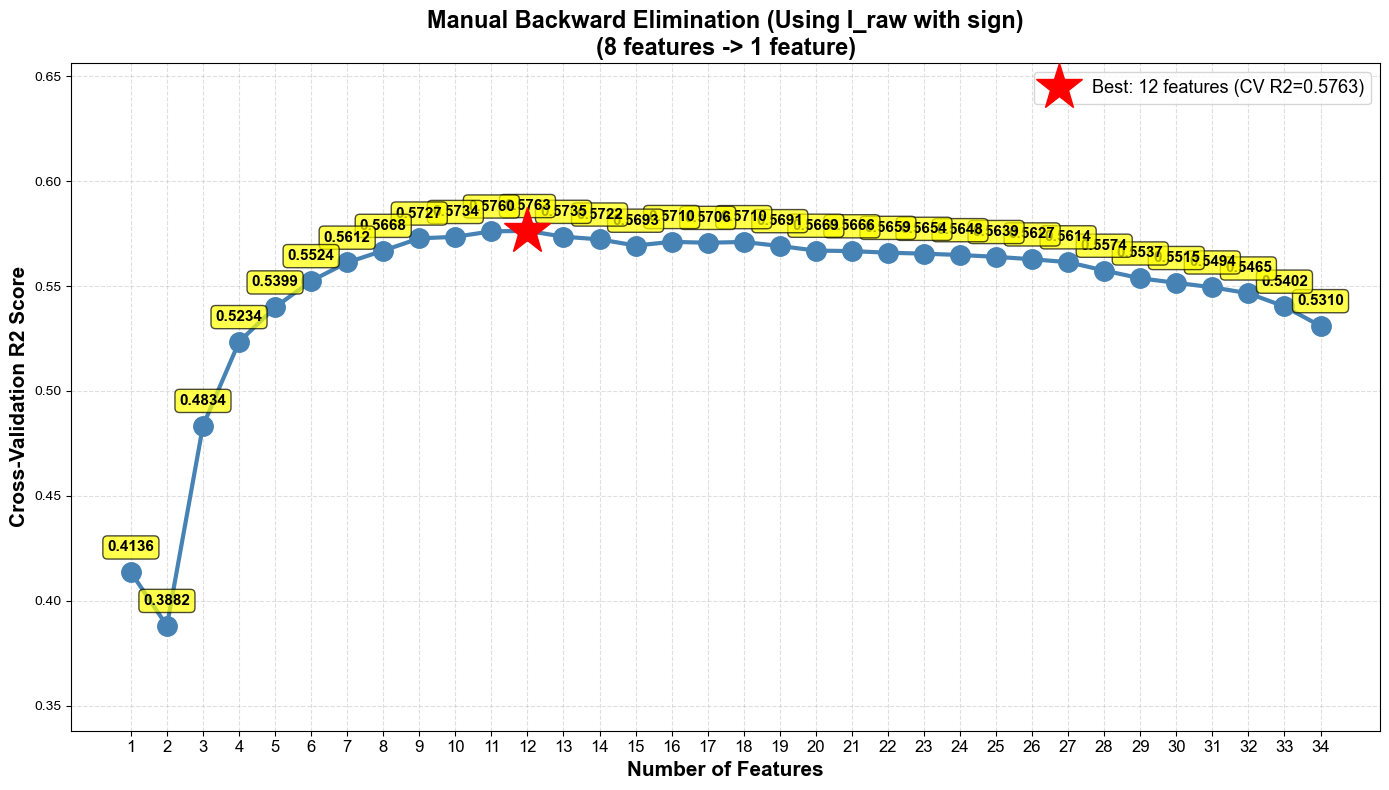

[OK] History saved to: 0-noble_no_BO_seed42\backward_elimination_I_raw_history.csv

BEST FEATURE CONFIGURATION
Number of features: 12
CV R2: 0.5763
Features: ['E_IR_corrected_final', 'I_raw', 'work_function_element2', 'MM_bond_element2', 'E_std_element1', 'E_std_element2', 'FE_ads_avg_element1', 'delta_EOH_element1', 'delta_EOH_element2', 'electronegativity_element1', 'MH_bond_kJ_element2', 'MD_bond_kJ_element2']

STEP 3: TRAINING MODELS WITH SELECTED FEATURES (Grid Search)

Using 12 selected features:
  1. E_IR_corrected_final
  2. I_raw
  3. work_function_element2
  4. MM_bond_element2
  5. E_std_element1
  6. E_std_element2
  7. FE_ads_avg_element1
  8. delta_EOH_element1
  9. delta_EOH_element2
  10. electronegativity_element1
  11. MH_bond_kJ_element2
  12. MD_bond_kJ_element2

--- Random Forest ---
Best params: {'max_depth': 10, 'min_samples_leaf': 2, 'min_samples_split': 2, 'n_estimators': 100}
Best CV score: 0.5776
Train R2: 0.8965, RMSE: 0.5388
Test R2: 0.6339, RMSE: 0.9716
Ov

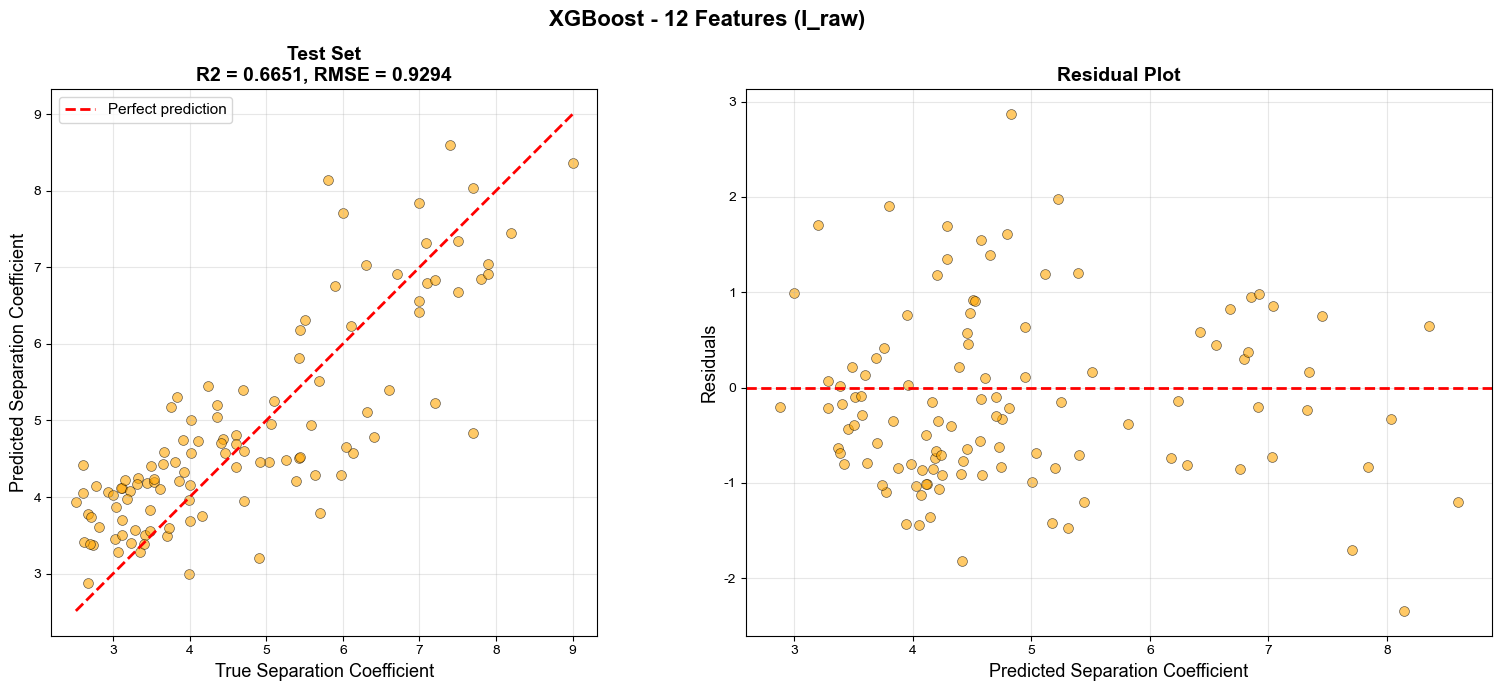


STEP 5: SHAP ANALYSIS

[DEBUG] dtypes of X_train before SHAP:
E_IR_corrected_final          float64
I_raw                         float64
work_function_element2        float64
MM_bond_element2              float64
E_std_element1                float64
E_std_element2                float64
FE_ads_avg_element1           float64
delta_EOH_element1            float64
delta_EOH_element2            float64
electronegativity_element1    float64
MH_bond_kJ_element2           float64
MD_bond_kJ_element2           float64
dtype: object

[DEBUG] dtypes of X_test before SHAP:
E_IR_corrected_final          float64
I_raw                         float64
work_function_element2        float64
MM_bond_element2              float64
E_std_element1                float64
E_std_element2                float64
FE_ads_avg_element1           float64
delta_EOH_element1            float64
delta_EOH_element2            float64
electronegativity_element1    float64
MH_bond_kJ_element2           float64
MD_bond_kJ

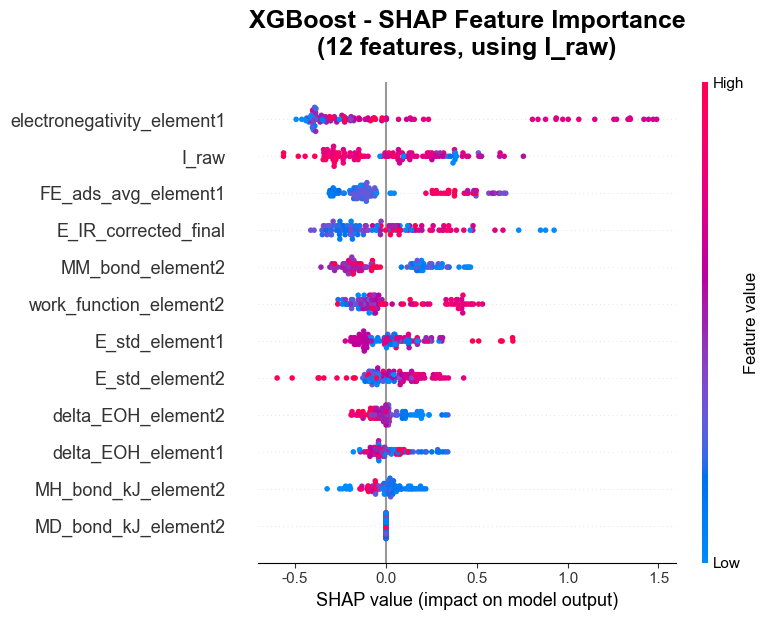

[OK] SHAP bar plot saved


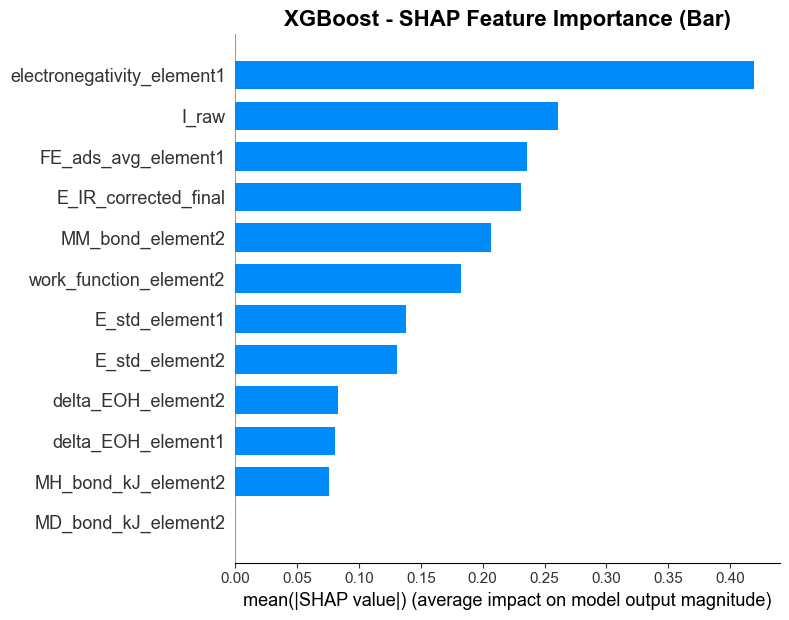


SHAP Feature Importance:
                   feature  shap_importance
electronegativity_element1         0.419276
                     I_raw         0.260914
       FE_ads_avg_element1         0.235509
      E_IR_corrected_final         0.230878
          MM_bond_element2         0.206821
    work_function_element2         0.182726
            E_std_element1         0.138377
            E_std_element2         0.130488
        delta_EOH_element2         0.083175
        delta_EOH_element1         0.080479
       MH_bond_kJ_element2         0.076039
       MD_bond_kJ_element2         0.000000

FINAL SUMMARY

Best model: XGBoost
Number of features: 12
Test R2: 0.6651
Test RMSE: 0.9294

Selected features:
  1. E_IR_corrected_final
  2. I_raw
  3. work_function_element2
  4. MM_bond_element2
  5. E_std_element1
  6. E_std_element2
  7. FE_ads_avg_element1
  8. delta_EOH_element1
  9. delta_EOH_element2
  10. electronegativity_element1
  11. MH_bond_kJ_element2
  12. MD_bond_kJ_element2

Key

In [10]:
# 把连续的 y 分箱，用于 "伪stratify"
y_bins = pd.qcut(y, q=10, labels=False, duplicates='drop')

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y_bins
)

print(f"\nData split: {X_train.shape[0]} train, {X_test.shape[0]} test")

# STEP 2: Backward Elimination
elimination_history = manual_backward_elimination(X_train, y_train, min_features=1)

# 绘制曲线
history_df = plot_elimination_curve(elimination_history, output_dir)

# 找到最优配置
max_idx = history_df['cv_r2'].idxmax()
best_config = history_df.loc[max_idx]
selected_features = best_config['features']

print(f"\n{'='*100}")
print(f"BEST FEATURE CONFIGURATION")
print(f"{'='*100}")
print(f"Number of features: {len(selected_features)}")
print(f"CV R2: {best_config['cv_r2']:.4f}")
print(f"Features: {selected_features}")

# STEP 3: 训练模型
best_model, results_df = train_models_with_selected_features(
    X_train, X_test, y_train, y_test, selected_features, output_dir
)

# STEP 4: 绘制预测图
plot_prediction(best_model, output_dir)

# STEP 5: SHAP分析
shap_importance = perform_shap_analysis(best_model, output_dir)

# 最终总结
print(f"\n{'='*100}")
print(f"FINAL SUMMARY")
print(f"{'='*100}")
print(f"\nBest model: {best_model['model_name']}")
print(f"Number of features: {len(selected_features)}")
print(f"Test R2: {best_model['test_r2']:.4f}")
print(f"Test RMSE: {best_model['test_rmse']:.4f}")

print(f"\nSelected features:")
for i, feat in enumerate(selected_features, 1):
    print(f"  {i}. {feat}")

print(f"\nKey insight:")
print(f"  Using I_raw (preserving positive/negative sign) instead of I_log")
print(f"  This allows the model to distinguish:")
print(f"    - Negative current: normal HER behavior")
print(f"    - Positive current: abnormal behavior (e.g., Zn dissolution)")

# print(f"\nAll results saved to: {output_dir}/")


Data split: 446 train, 112 test

STEP 2: MANUAL BACKWARD ELIMINATION (8 -> 1 features)

Estimator: Random Forest (optimized parameters)
Starting with 33 features

Step 1: 33 features
Current features: ['Rct_log', 'Cp_log', 'Rp_log', 'C_dl_log', 'tafel_slope', 'W_sigma_log', 'I_raw', 'work_function_element1', 'work_function_element2', 'pzc_element1', 'pzc_element2', 'MM_bond_element1', 'MM_bond_element2', 'E_std_element1', 'E_std_element2', 'FE_ads_avg_element1', 'FE_ads_avg_element2', 'delta_EOH_element1', 'delta_EOH_element2', 'electronegativity_element1', 'electronegativity_element2', 'MH_bond_kJ_element1', 'MH_bond_kJ_element2', 'MD_bond_kJ_element1', 'MD_bond_kJ_element2', 'Frequency_OH_element1', 'Frequency_OH_element2', 'Frequency_H_element1', 'Frequency_H_element2', 'Frequency_D_element1', 'Frequency_D_element2', 'delta_ZPE_H_element1', 'delta_ZPE_H_element2']
Current CV R2: 0.5204

Trying to remove each feature:
  Remove 'Rct_log': CV R2 = 0.5229 (change: +0.0025)
  Remove 'Cp

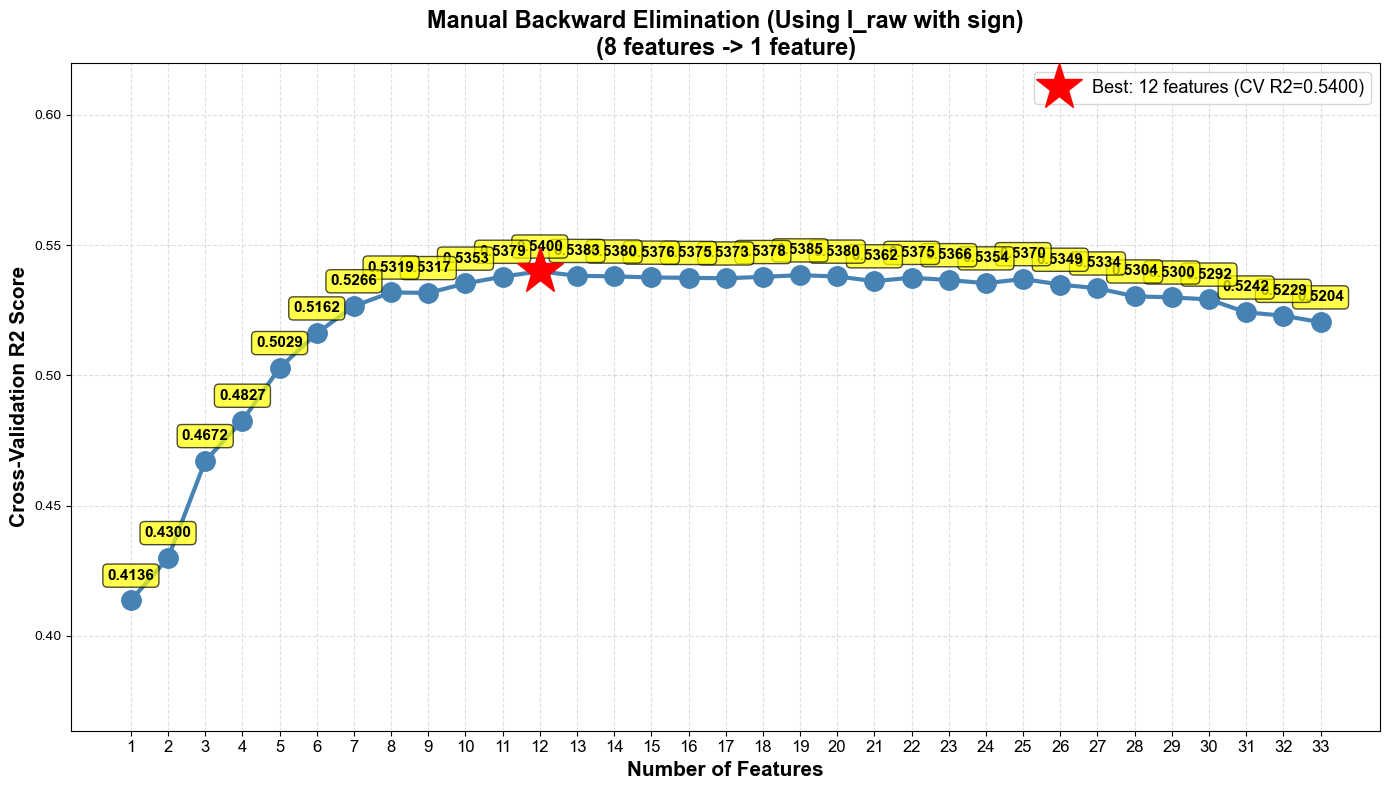

[OK] History saved to: 0-noble_no_BO_seed42\backward_elimination_I_raw_history.csv

BEST FEATURE CONFIGURATION
Number of features: 12
CV R2: 0.5400
Features: ['I_raw', 'work_function_element2', 'MM_bond_element1', 'MM_bond_element2', 'E_std_element1', 'E_std_element2', 'FE_ads_avg_element1', 'delta_EOH_element2', 'electronegativity_element1', 'electronegativity_element2', 'MH_bond_kJ_element2', 'MD_bond_kJ_element1']

STEP 3: TRAINING MODELS WITH SELECTED FEATURES (Grid Search)

Using 12 selected features:
  1. I_raw
  2. work_function_element2
  3. MM_bond_element1
  4. MM_bond_element2
  5. E_std_element1
  6. E_std_element2
  7. FE_ads_avg_element1
  8. delta_EOH_element2
  9. electronegativity_element1
  10. electronegativity_element2
  11. MH_bond_kJ_element2
  12. MD_bond_kJ_element1

--- Random Forest ---
Best params: {'max_depth': 10, 'min_samples_leaf': 2, 'min_samples_split': 2, 'n_estimators': 100}
Best CV score: 0.5434
Train R2: 0.8916, RMSE: 0.5515
Test R2: 0.6574, RMSE: 0

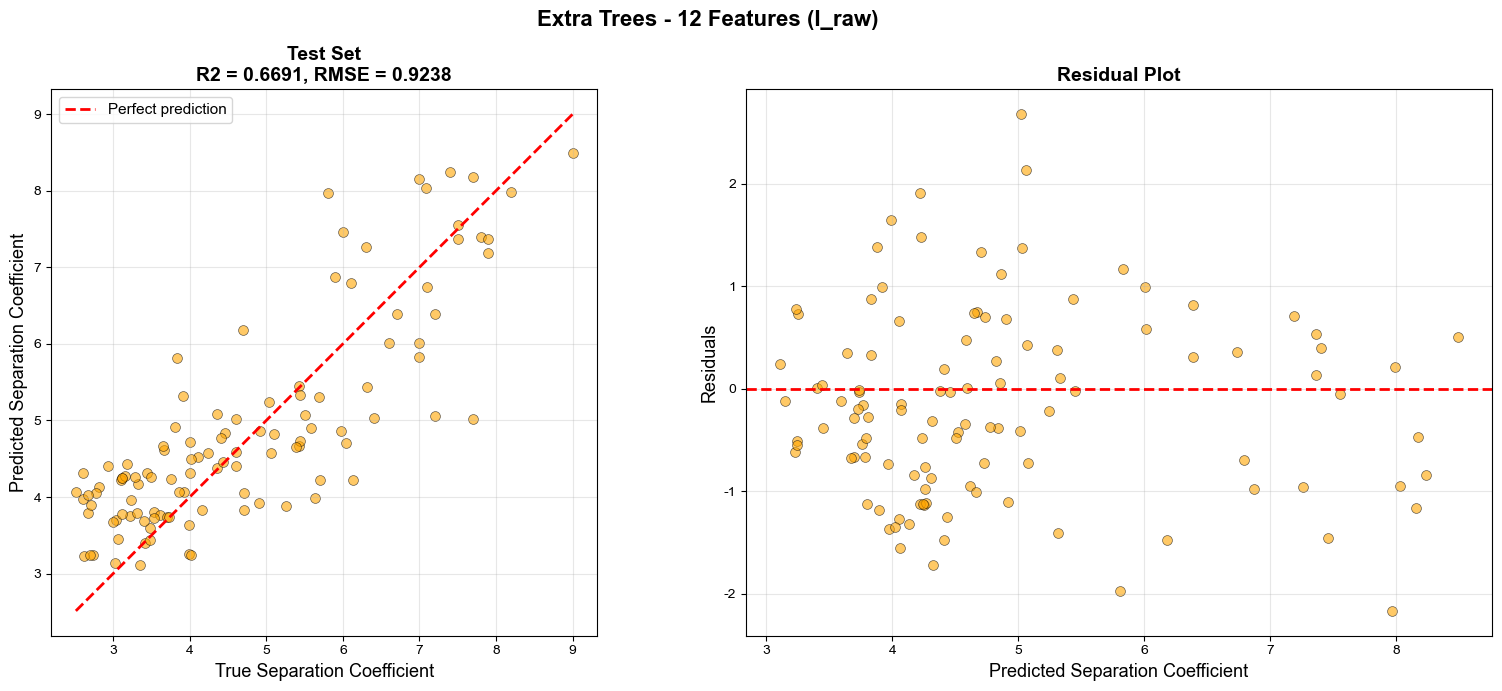


STEP 5: SHAP ANALYSIS

[DEBUG] dtypes of X_train before SHAP:
I_raw                         float64
work_function_element2        float64
MM_bond_element1              float64
MM_bond_element2              float64
E_std_element1                float64
E_std_element2                float64
FE_ads_avg_element1           float64
delta_EOH_element2            float64
electronegativity_element1    float64
electronegativity_element2    float64
MH_bond_kJ_element2           float64
MD_bond_kJ_element1           float64
dtype: object

[DEBUG] dtypes of X_test before SHAP:
I_raw                         float64
work_function_element2        float64
MM_bond_element1              float64
MM_bond_element2              float64
E_std_element1                float64
E_std_element2                float64
FE_ads_avg_element1           float64
delta_EOH_element2            float64
electronegativity_element1    float64
electronegativity_element2    float64
MH_bond_kJ_element2           float64
MD_bond_kJ

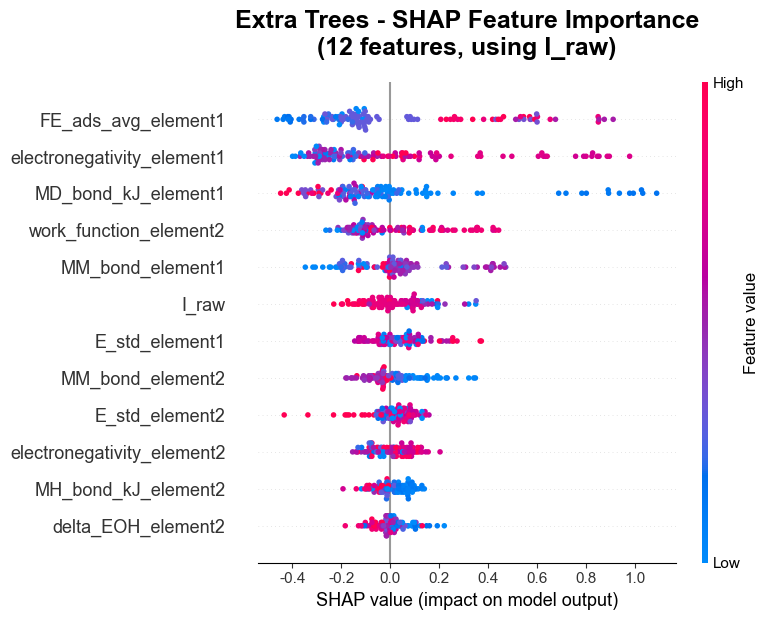

[OK] SHAP bar plot saved


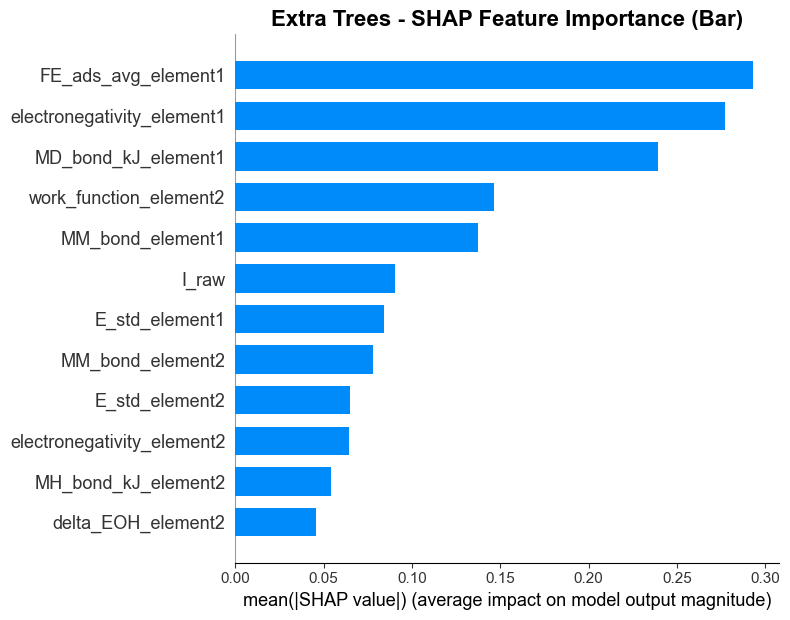


SHAP Feature Importance:
                   feature  shap_importance
       FE_ads_avg_element1         0.293193
electronegativity_element1         0.276994
       MD_bond_kJ_element1         0.239471
    work_function_element2         0.146449
          MM_bond_element1         0.137198
                     I_raw         0.090695
            E_std_element1         0.084071
          MM_bond_element2         0.077999
            E_std_element2         0.065156
electronegativity_element2         0.064480
       MH_bond_kJ_element2         0.054153
        delta_EOH_element2         0.045862

FINAL SUMMARY

Best model: Extra Trees
Number of features: 12
Test R2: 0.6691
Test RMSE: 0.9238

Selected features:
  1. I_raw
  2. work_function_element2
  3. MM_bond_element1
  4. MM_bond_element2
  5. E_std_element1
  6. E_std_element2
  7. FE_ads_avg_element1
  8. delta_EOH_element2
  9. electronegativity_element1
  10. electronegativity_element2
  11. MH_bond_kJ_element2
  12. MD_bond_kJ_eleme

In [11]:
X = X.drop(columns=["E_IR_corrected_final"])

# 把连续的 y 分箱，用于 "伪stratify"
y_bins = pd.qcut(y, q=10, labels=False, duplicates='drop')

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y_bins
)

print(f"\nData split: {X_train.shape[0]} train, {X_test.shape[0]} test")

# STEP 2: Backward Elimination
elimination_history = manual_backward_elimination(X_train, y_train, min_features=1)

# 绘制曲线
history_df = plot_elimination_curve(elimination_history, output_dir)

# 找到最优配置
max_idx = history_df['cv_r2'].idxmax()
best_config = history_df.loc[max_idx]
selected_features = best_config['features']

print(f"\n{'='*100}")
print(f"BEST FEATURE CONFIGURATION")
print(f"{'='*100}")
print(f"Number of features: {len(selected_features)}")
print(f"CV R2: {best_config['cv_r2']:.4f}")
print(f"Features: {selected_features}")

# STEP 3: 训练模型
best_model, results_df = train_models_with_selected_features(
    X_train, X_test, y_train, y_test, selected_features, output_dir
)

# STEP 4: 绘制预测图
plot_prediction(best_model, output_dir)

# STEP 5: SHAP分析
shap_importance = perform_shap_analysis(best_model, output_dir)

# 最终总结
print(f"\n{'='*100}")
print(f"FINAL SUMMARY")
print(f"{'='*100}")
print(f"\nBest model: {best_model['model_name']}")
print(f"Number of features: {len(selected_features)}")
print(f"Test R2: {best_model['test_r2']:.4f}")
print(f"Test RMSE: {best_model['test_rmse']:.4f}")

print(f"\nSelected features:")
for i, feat in enumerate(selected_features, 1):
    print(f"  {i}. {feat}")

print(f"\nKey insight:")
print(f"  Using I_raw (preserving positive/negative sign) instead of I_log")
print(f"  This allows the model to distinguish:")
print(f"    - Negative current: normal HER behavior")
print(f"    - Positive current: abnormal behavior (e.g., Zn dissolution)")

# print(f"\nAll results saved to: {output_dir}/")


BEST FEATURE CONFIGURATION
Number of features: 11
Features: ['Rp_log', 'C_dl_log', 'I_raw', 'work_function_element1', 'work_function_element2', 'MM_bond_element2', 'E_std_element1', 'E_std_element2', 'FE_ads_avg_element1', 'delta_EOH_element2', 'electronegativity_element1']

STEP 3: TRAINING MODELS WITH SELECTED FEATURES (Grid Search)

Using 11 selected features:
  1. Rp_log
  2. C_dl_log
  3. I_raw
  4. work_function_element1
  5. work_function_element2
  6. MM_bond_element2
  7. E_std_element1
  8. E_std_element2
  9. FE_ads_avg_element1
  10. delta_EOH_element2
  11. electronegativity_element1

--- Random Forest ---
Best params: {'max_depth': None, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 200}
Best CV score: 0.5343
Train R2: 0.9378, RMSE: 0.4177
Test R2: 0.5726, RMSE: 1.0499
Overfitting: 0.3652

--- Extra Trees ---
Best params: {'max_depth': None, 'min_samples_leaf': 1, 'min_samples_split': 5, 'n_estimators': 100}
Best CV score: 0.5391
Train R2: 0.9724, RMSE: 

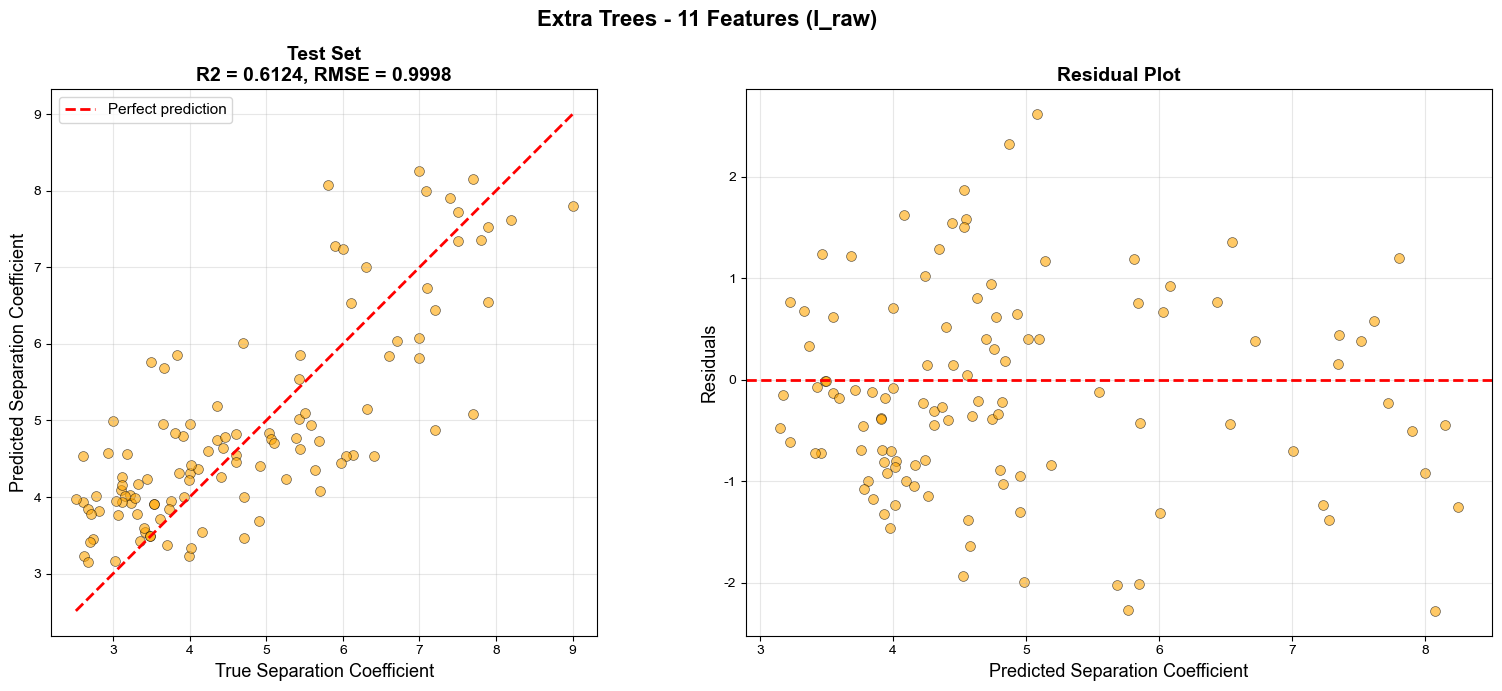


STEP 5: SHAP ANALYSIS

[DEBUG] dtypes of X_train before SHAP:
Rp_log                        float64
C_dl_log                      float64
I_raw                         float64
work_function_element1        float64
work_function_element2        float64
MM_bond_element2              float64
E_std_element1                float64
E_std_element2                float64
FE_ads_avg_element1           float64
delta_EOH_element2            float64
electronegativity_element1    float64
dtype: object

[DEBUG] dtypes of X_test before SHAP:
Rp_log                        float64
C_dl_log                      float64
I_raw                         float64
work_function_element1        float64
work_function_element2        float64
MM_bond_element2              float64
E_std_element1                float64
E_std_element2                float64
FE_ads_avg_element1           float64
delta_EOH_element2            float64
electronegativity_element1    float64
dtype: object

[DEBUG] All X_train and X_test co

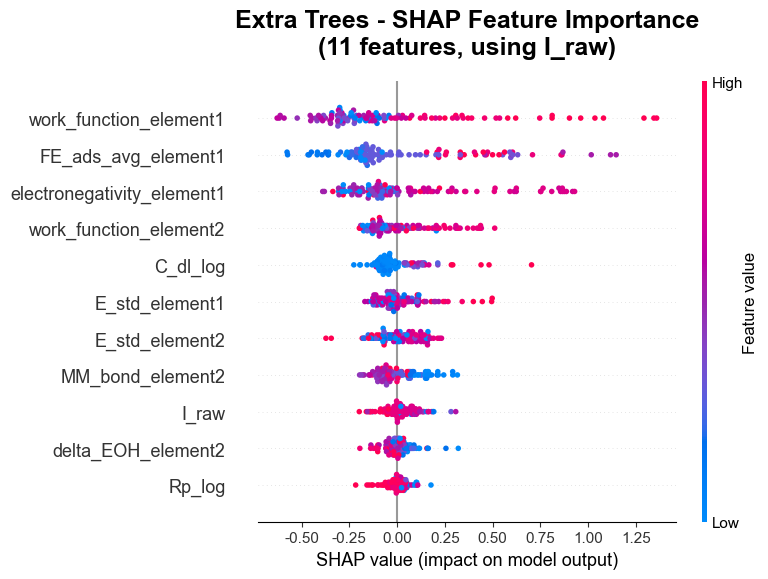

[OK] SHAP bar plot saved


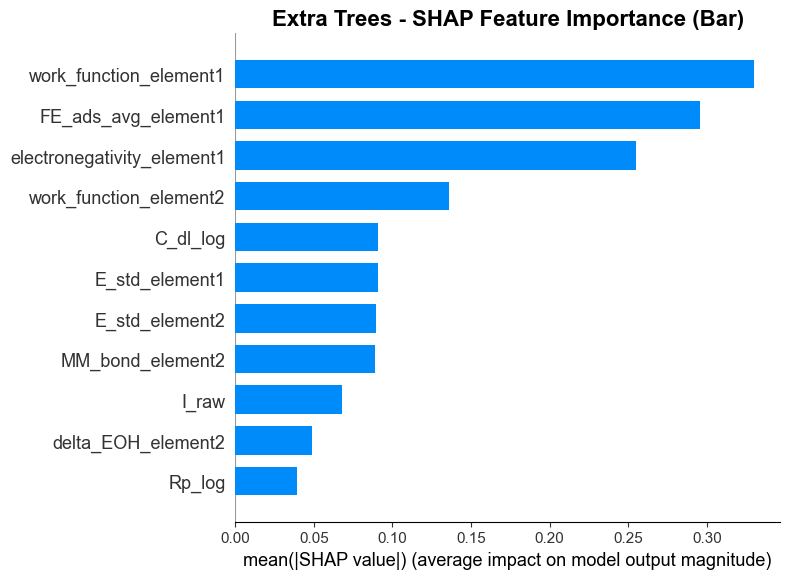


SHAP Feature Importance:
                   feature  shap_importance
    work_function_element1         0.330035
       FE_ads_avg_element1         0.295804
electronegativity_element1         0.254765
    work_function_element2         0.135712
                  C_dl_log         0.090997
            E_std_element1         0.090657
            E_std_element2         0.089247
          MM_bond_element2         0.089024
                     I_raw         0.068088
        delta_EOH_element2         0.048552
                    Rp_log         0.039306

FINAL SUMMARY

Best model: Extra Trees
Number of features: 11
Test R2: 0.6124
Test RMSE: 0.9998

Selected features:
  1. Rp_log
  2. C_dl_log
  3. I_raw
  4. work_function_element1
  5. work_function_element2
  6. MM_bond_element2
  7. E_std_element1
  8. E_std_element2
  9. FE_ads_avg_element1
  10. delta_EOH_element2
  11. electronegativity_element1

Key insight:
  Using I_raw (preserving positive/negative sign) instead of I_log
  This all

In [12]:
X = X_copy.drop(columns=["E_IR_corrected_final"])

# 把连续的 y 分箱，用于 "伪stratify"
y_bins = pd.qcut(y, q=10, labels=False, duplicates='drop')

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y_bins
)

selected_features =  ['Rp_log', 'C_dl_log', 'I_raw', 'work_function_element1', 'work_function_element2', 'MM_bond_element2', 'E_std_element1', 'E_std_element2', 'FE_ads_avg_element1', 'delta_EOH_element2', 'electronegativity_element1']

print(f"\n{'='*100}")
print(f"BEST FEATURE CONFIGURATION")
print(f"{'='*100}")
print(f"Number of features: {len(selected_features)}")
print(f"Features: {selected_features}")

# STEP 3: 训练模型
best_model, results_df = train_models_with_selected_features(
    X_train, X_test, y_train, y_test, selected_features, output_dir
)

# STEP 4: 绘制预测图
plot_prediction(best_model, output_dir)

# STEP 5: SHAP分析
shap_importance = perform_shap_analysis(best_model, output_dir)

# 最终总结
print(f"\n{'='*100}")
print(f"FINAL SUMMARY")
print(f"{'='*100}")
print(f"\nBest model: {best_model['model_name']}")
print(f"Number of features: {len(selected_features)}")
print(f"Test R2: {best_model['test_r2']:.4f}")
print(f"Test RMSE: {best_model['test_rmse']:.4f}")

print(f"\nSelected features:")
for i, feat in enumerate(selected_features, 1):
    print(f"  {i}. {feat}")

print(f"\nKey insight:")
print(f"  Using I_raw (preserving positive/negative sign) instead of I_log")
print(f"  This allows the model to distinguish:")
print(f"    - Negative current: normal HER behavior")
print(f"    - Positive current: abnormal behavior (e.g., Zn dissolution)")

print(f"\nAll results saved to: {output_dir}/")